# UPI Spending Analysis

## Project Overview

This project analyses six months of personal UPI transaction data from January to June 2026 extracted from a Google Pay transaction statement

The workflow covers PDF- based transaction extraction, data cleaning, feature engineering, transaction categorisation and exploratory data analysis.

### Tools
Python · Pandas · Matplotlib · pdfplumber

### Analytical Focus
- Spending trends over time
- Category and merchant- level expenditure
- Transaction behaviour 
- Paid vs Received money flow
- Spending concentration
- Data quality and categorisation challenges

## Objectives

- Compare money paid and received
- Analyse monthly spending patterns
- Identify major spending categories
- Identify top merchants by total spending
- Analyse transaction frequency and average transaction value
- Analyse weekday vs weekend spending
- Examine spending concentration across merchants/categories
- Identify top 10% concentration analysis

1. IMPORT LIBRARIES

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import pdfplumber


2. DATA EXTRACTION

In [41]:
pdf_path="/home/paragchengappa/programming/UPI-Spending-Analyser/data/raw/bankstats.pdf"
text=""   # called an accumulator, stores all text

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        page_text=page.extract_text()
        if page_text:
            text+=page_text+ "\n"         
print(text[:2000])


Transaction statement
9019517497, paragchengappa@gmail.com
Transactionstatementperiod Sent Received
01January2026-30June2026 ₹77,368.99 ₹70,536
Date&time Transactiondetails Amount
03Jan,2026 PaidtoJAYARAMAPB ₹30
07:41AM UPITransactionID:600358945338
PaidbyStateBankofIndia7202
03Jan,2026 PaidtoSHIVANNA SHIVANNA ₹231
02:17PM UPITransactionID:636962750553
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoPARASHURAMA ₹56.15
07:29AM UPITransactionID:600553332781
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoRAMESHMR ₹5
09:45AM UPITransactionID:600558105853
PaidbyStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹1,100
01:14PM UPITransactionID:969952655934
PaidtoStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹300
01:19PM UPITransactionID:527376183990
PaidtoStateBankofIndia7202
05Jan,2026 PaidtoBlinkit ₹1,112
01:19PM UPITransactionID:637121529011
PaidbyStateBankofIndia7202
06Jan,2026 PaidtoBMTCBUSKA57F1114 ₹15
12:03PM UPITransactionID:600608819250
PaidbyStateBankofIndia7202
Note:Th

In [42]:
transactions=[]

In [43]:
lines=text.splitlines()

In [45]:
import re
i=0

while i<len(lines):
    line=lines[i]

    if re.match(r"\d{2}[A-Za-z]{3,9},\d{4}",line):
        line1=lines[i]
        line2=lines[i+1]
        line3=lines[i+2]

        date=re.search(r"\d{2}[A-Za-z]{3,9},\d{4}",line1).group()

        amount=re.search(r"₹[\d,\.]+",line1).group()

        details=line1.replace(date,"")             #details=string after replacing date w "" from line1
        details=details.replace(amount,"").strip() #details=replace amount from DETAILS w ""
                                                   #strip blank spaces "","" which replaced date and amount
                                                   #and then assign to details

        time=re.search(r"\d{2}:\d{2}[AP]M",line2).group()

        upi=re.search(r"\d{12}",line2).group()
        bank=line3                                 # since in text, third line of each transaction is Paidby/toStateBankOfIndia

        transactions.append([date,time,details,amount,upi,bank])
        i+=3
    else:
        i+=1
                


In [46]:
df=pd.DataFrame(transactions,columns=["Date","Time","Details","Amount","UPI_ID","Bank"])
df.head()

,Date,Time,Details,Amount,UPI_ID,Bank
0,"03Jan,2026",07:41AM,PaidtoJAYARAMAPB,₹30,600358945338,PaidbyStateBankofIndia7202
1,"03Jan,2026",02:17PM,PaidtoSHIVANNA SHIVANNA,₹231,636962750553,PaidbyStateBankofIndia7202
2,"05Jan,2026",07:29AM,PaidtoPARASHURAMA,₹56.15,600553332781,PaidbyStateBankofIndia7202
3,"05Jan,2026",09:45AM,PaidtoRAMESHMR,₹5,600558105853,PaidbyStateBankofIndia7202
4,"05Jan,2026",01:14PM,ReceivedfromMC NALINAKSHI,"₹1,100",969952655934,PaidtoStateBankofIndia7202


3. DATA CLEANING

The extracted transaction data was cleaned and standardised before analysis

In [47]:
df["Date"]=pd.to_datetime(df["Date"],format= "%d%b,%Y")
df["Amount"]=(df["Amount"].str.replace("₹","",regex=False)
              .str.replace(",","",regex=False))
df["Amount"]=df["Amount"].astype(float)
df.info
df.isnull().sum()
df.duplicated().sum()

0

In [48]:
print(df["Details"])

0               PaidtoJAYARAMAPB
1        PaidtoSHIVANNA SHIVANNA
2              PaidtoPARASHURAMA
3                 PaidtoRAMESHMR
4      ReceivedfromMC NALINAKSHI
                 ...            
508            PaidtoAmazonIndia
509    ReceivedfromMC NALINAKSHI
510                 PaidtoMyntra
511    ReceivedfromMC NALINAKSHI
512                PaidtoBlinkit
Name: Details, Length: 513, dtype: object


### Data Quality
The extracted dataset contains 513 transactions with no missing values and no duplicate rows

4. FEATURE ENGINEERING

In [49]:
df["Transaction_Type"]=df["Details"].str.contains(r"Paid",case=False, na=False).map({True:"Paid",
                                                                                     False:"Received"
                                                                                    })

In [50]:
df["Merchant"]= df["Details"].str.replace("Paidto","",regex=False).str.replace("Receivedfrom","",regex=False).str.strip().str.title()
print(df["Merchant"])

0             Jayaramapb
1      Shivanna Shivanna
2            Parashurama
3               Rameshmr
4          Mc Nalinakshi
             ...        
508          Amazonindia
509        Mc Nalinakshi
510               Myntra
511        Mc Nalinakshi
512              Blinkit
Name: Merchant, Length: 513, dtype: object


In [51]:
df["Day"]=df["Date"].dt.day
df["Day_Name"]=df["Date"].dt.day_name()



In [52]:
month_order=["January","February","March","April","May","June","July","August","September","October","November","December"]
df["Month"]=pd.Categorical(df["Date"].dt.month_name(),categories=month_order,ordered=True)
df["Year"]=df["Date"].dt.year

In [53]:
df["Bank"]=(df["Bank"].str.replace("Paidto","",regex=False).str.replace("Paidby","",regex=False).str.strip())

In [54]:
df.head()

,Date,Time,Details,Amount,UPI_ID,Bank,Transaction_Type,Merchant,Day,Day_Name,Month,Year
0,2026-01-03,07:41AM,PaidtoJAYARAMAPB,30.00,600358945338,StateBankofIndia7202,Paid,Jayaramapb,3,Saturday,January,2026
1,2026-01-03,02:17PM,PaidtoSHIVANNA SHIVANNA,231.00,636962750553,StateBankofIndia7202,Paid,Shivanna Shivanna,3,Saturday,January,2026
2,2026-01-05,07:29AM,PaidtoPARASHURAMA,56.15,600553332781,StateBankofIndia7202,Paid,Parashurama,5,Monday,January,2026
3,2026-01-05,09:45AM,PaidtoRAMESHMR,5.00,600558105853,StateBankofIndia7202,Paid,Rameshmr,5,Monday,January,2026
4,2026-01-05,01:14PM,ReceivedfromMC NALINAKSHI,1100.00,969952655934,StateBankofIndia7202,Received,Mc Nalinakshi,5,Monday,January,2026


In [55]:
print(df["Merchant"].unique())

['Jayaramapb' 'Shivanna Shivanna' 'Parashurama' 'Rameshmr' 'Mc Nalinakshi'
 'Blinkit' 'Bmtcbuska57F1114' 'Smartbazaar Bengalurufr47' 'Ka01Ar2969'
 'Mrajeshwaribai' 'Shaik Saleem' 'Sudhakar Chitikela' 'Ganagaraja'
 'Elwineapenm' 'Govindar' 'Aatreyobhattacharya' 'Sadashiva'
 'Veeralchengappa' 'Zepto' 'Ranjancssoshankaregowdat' 'Ka01Ar2872'
 'Swiggy' 'Zeptomarketplaceprivatelimited' 'Ridafathimakhanum'
 'Ka01Ar1160' 'Zeptonow' 'Greentrends' 'Mslifecaremedicals21'
 'Bmtcbuska57F2179' 'Saniya Sultana' 'Soha' 'Mrssaraswathi Ganesan'
 'Lipikasridhar' 'Manjunathahn' 'Mrchennegowda Kc' 'Ssfoodandbeverage'
 'Mrnishanthgowdacm' 'Nagaraja' 'Zabeeralikm' 'Nitikaagarwal'
 'Kishankumar' 'Erannahm' 'Ka51Al6812' 'Mahendrahk' 'Venkateshg'
 'Abhishekr' 'Mr Harshith R' 'Mabu' 'Kumara' 'Spotifyindialip'
 'Manikantas' 'Manjunatha' 'Vigneshvenkatesh' 'Lafemmebeautysaloon'
 'Kavithastores' 'Syedafroz' 'Chaiculture' 'Muskan' 'S Appu'
 'Abhishekshankinamath' 'Bundltechnologiespvtltd' 'Chandrashekhargowda'
 'Aam

5. MERCHANT NORMALIZATION AND CATEGORY MAPPING

In [56]:
merchant_category={
            "Groceries":{
                "Blinkit":[r"Blinkit"],
                "Swiggy Instamart":[r"Swiggy\s*instamart|Instamart"],
                "Zepto":[r"Zepto|zepto"],
                "Supermarkets":[r"Superstore|Smartbazaar|More|Fruits|Vegetables|Farmer"]
                },
            "Transport":{
                "Transport":[r"Ka{2}/d|Bmtc*|Bmrcl*|Kstrc"]
                },
            "Food":{
                "Swiggy":[r"Swiggy|Bundltechnologiespvtltd"],
                "Zomato":[r"Zomato"],
                "Ownly":[r"Ownly"],
                "MiscFood":[r"Chats|Cafe|Restaurant|Bakes|Food|Beverage|Chai|Coffee|Juice|Bar|Houseofcommonsjpnagar|Thecoral"]
                },
            "Personal_Transfers":{
                "Personal Transfer":[r"Mc nalinakshi|Nalinichengappa|Veeralchengappa|Elwin\s*eapen|Elwin|Sachins|Nitikaagarwal|Lipikasridhar|Aatreyobhattacharya|Mr harshith r|Aryanbhushan"]
                },
           "Shopping":{
                "Amazon":[r"Amazon|Amzn"],
                "Flipkart":[r"Flipkart"],
                "Myntra":[r"Myntra"],
                "Nykaa":[r"NykaaFashion|NykaaMakeup|Nykaa"],
                "H&M":[r"HennesandMauritz|HandM|H&M"],
                "SmartBazaar":[r"Justvendprivatelimited"]
            },
            "Salon":{
                "Salon":[r"Beauty|Glamour|Glam|Gorgeous|Salon|Parlour|Spa"],
                "GreenTrends":[r"Greentrends"]
            },
            "Misc":{
                "Recharge":[r"Prepaid|Postpaid"],
                "Stationers":[r"Rameshmr|Mrramesh|Stationers|Bookhouse|Books"],
                "Subsciptions":[r"Spotify|Amazonprime|Netflix|Hotstar"],
                "Online Payments":[r"Amazon pay|Razorpay|Googleplay|Educationpvtltd"]
            },
}

In [57]:
import re

def assign_category(merchant_name):
    if not isinstance(merchant_name, str):
        return "Other"
    text_lower = merchant_name.lower()

    for category, merchants in merchant_category.items():
        for cleanname, patterns in merchants.items():
            for pattern in patterns:
                if re.search(pattern, text_lower, re.IGNORECASE):
                    return category 
    return "Other"
df["Category"] = df["Merchant"].apply(assign_category)

In [58]:
print(df["Category"].value_counts())

Other                 192
Personal_Transfers    159
Groceries              79
Misc                   33
Food                   24
Transport              13
Shopping                7
Salon                   6
Name: Category, dtype: int64


5. EXPLORATORY DATA ANALYSIS

a. TOTAL PAID VS RECEIVED

In [59]:
money_flow=df.groupby("Transaction_Type")["Amount"].sum()
money_flow

Transaction_Type
Paid        77368.99
Received    70536.00
Name: Amount, dtype: float64

b. MONTHLY SPENDING BREAKDOWN

In [ ]:
monthly_flow=df.groupby(["Month","Transaction_Type"],observed=True)["Amount"].sum().unstack(fill_value=0).reset_index()
monthly_flow

Transaction_Type,Month,Paid,Received
0,January,14027.44,14502.0
1,February,22120.71,19572.0
2,March,10446.02,9000.0
3,April,7140.82,7351.0
4,May,13462.00,13184.0
5,June,10172.00,6927.0


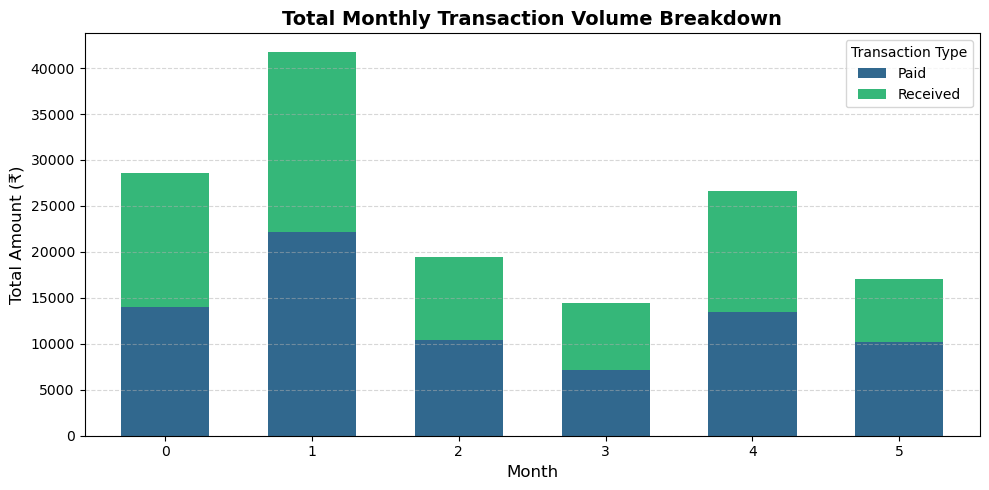

In [61]:
paidrecievedflow= monthly_flow.plot(
    kind="bar",
    stacked=True, # Stacks Received on top of Paid
    figsize=(10, 5),
    color=sns.color_palette("viridis", 2),
    width=0.6
)

plt.title("Total Monthly Transaction Volume Breakdown", fontsize=14, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Amount (₹)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(title="Transaction Type", frameon=True)

plt.tight_layout()
plt.show()

c. WEEKEND VS WEEKDAY SPENDING

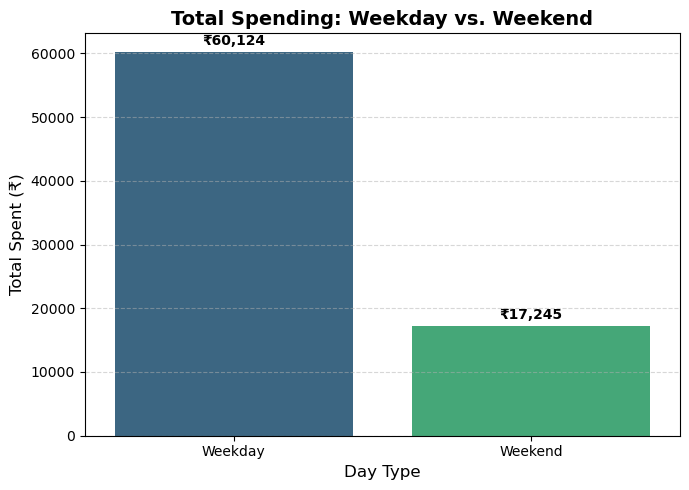

In [62]:
df["Day_Type"] = np.where(df["Day_Name"].isin(["Saturday", "Sunday"]), "Weekend", "Weekday")

weekday_vs_weekend = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Day_Type", observed=True)["Amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=weekday_vs_weekend,
    x="Day_Type",
    y="Amount",
    palette="viridis"
)

barlabels = [f"₹{height:,.0f}" for height in ax.containers[0].datavalues]
ax.bar_label(ax.containers[0],labels=barlabels, padding=3, fontweight="bold")

plt.title("Total Spending: Weekday vs. Weekend", fontsize=14, fontweight="bold")
plt.xlabel("Day Type", fontsize=12)
plt.ylabel("Total Spent (₹)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
plt.close()

d. SPENDING BY CATEGORY

In [63]:
category_spending=(df[df["Transaction_Type"]=="Paid"].groupby("Category")["Amount"].sum().sort_values(ascending=False).reset_index())
category_spending

,Category,Amount
0,Groceries,36151.24
1,Other,17263.03
2,Personal_Transfers,8209.00
3,Shopping,7297.00
4,Food,4001.82
5,Salon,2375.90
6,Misc,1456.00
7,Transport,615.00


In [64]:
maxamount=category_spending["Amount"].max()

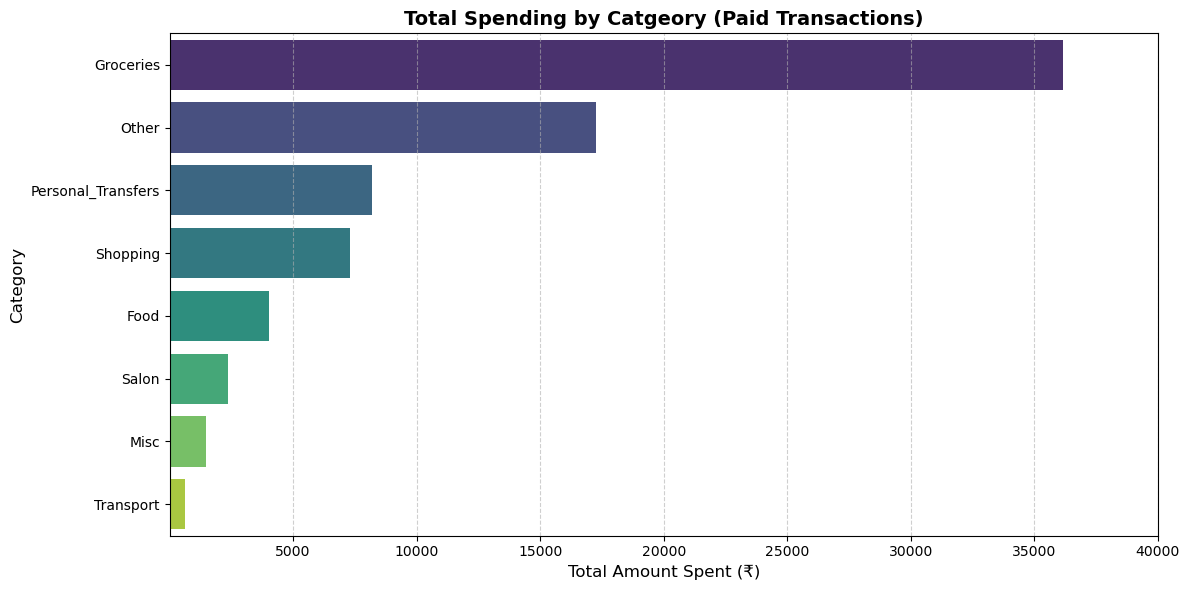

In [65]:
plt.figure(figsize=(12,6))
sns.barplot(
    data=category_spending,
    x="Amount",
    y="Category",
    palette="viridis"
)

x_ticks=np.arange(start=5000,stop=maxamount+5000,step=5000)
plt.xticks(ticks=x_ticks)

plt.title("Total Spending by Catgeory (Paid Transactions)",fontsize=14,fontweight="bold")
plt.xlabel("Total Amount Spent (₹)",fontsize=12)
plt.ylabel("Category",fontsize=12)
plt.grid(axis="x",linestyle="--",alpha=0.6)

plt.tight_layout()
plt.show()

In [66]:
category_perc = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Category")["Amount"]
    .sum()
    .reset_index()
    .assign(Percentage=lambda x: (x["Amount"] / x["Amount"].sum()) * 100).round(2)
    .sort_values(by="Percentage", ascending=False)
    .reset_index(drop=True)
)

print(category_perc)

             Category    Amount  Percentage
0           Groceries  36151.24       46.73
1               Other  17263.03       22.31
2  Personal_Transfers   8209.00       10.61
3            Shopping   7297.00        9.43
4                Food   4001.82        5.17
5               Salon   2375.90        3.07
6                Misc   1456.00        1.88
7           Transport    615.00        0.79


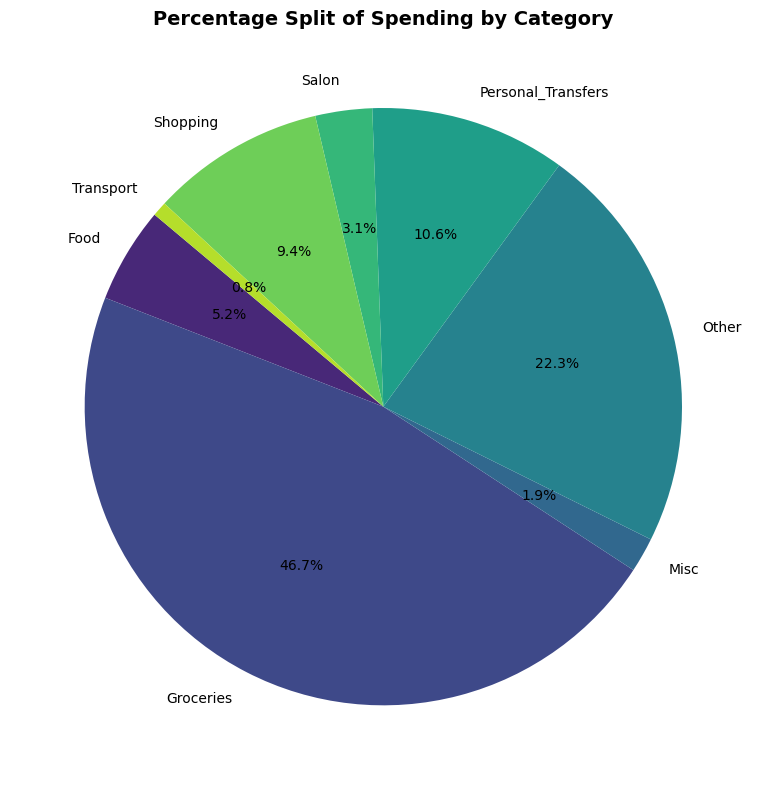

In [67]:
paid_ctg=df[df["Transaction_Type"]=="Paid"].groupby("Category")["Amount"].sum()

color=sns.color_palette("viridis",len(paid_ctg))

plt.figure(figsize=(8,8))
plt.pie(
    paid_ctg,
    labels=paid_ctg.index,
    colors=color,
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Percentage Split of Spending by Category",fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

e. BREAKDOWN OF PERSONAL TRANSFERS CATEGORY

In [68]:
Personal_Spending_Breakdown=df[(df["Category"]=="Personal_Transfers")&(df["Transaction_Type"]=="Paid")]
maxamountpt=Personal_Spending_Breakdown["Amount"].max()

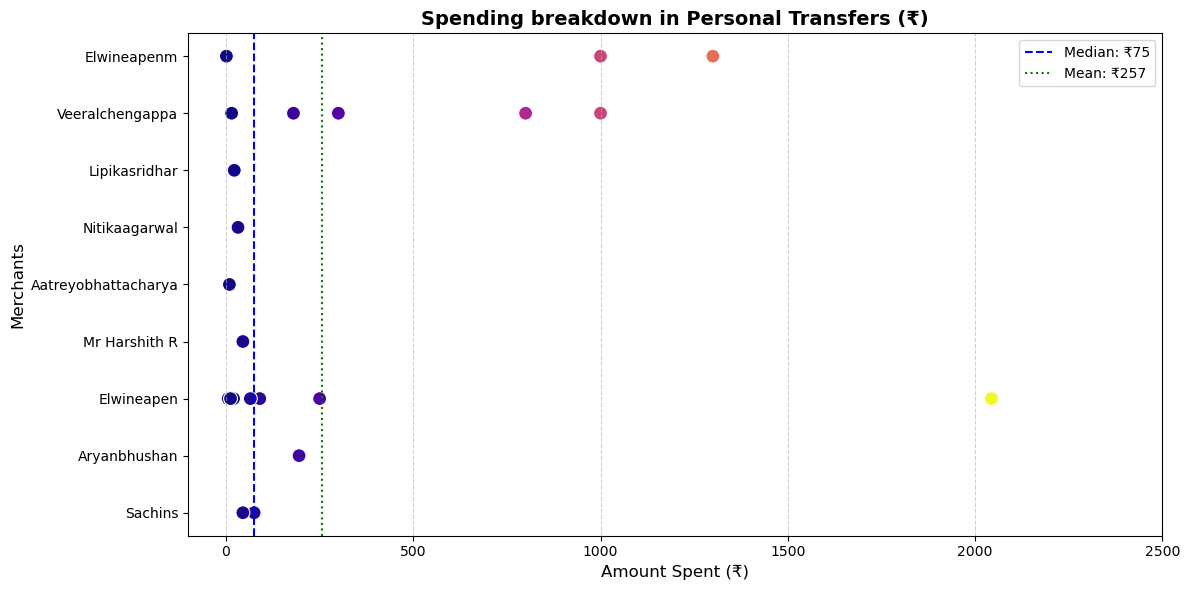

In [69]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    data=Personal_Spending_Breakdown,
    x="Amount",
    y="Merchant",
    hue="Amount",
    palette="plasma",
    s=100,
    legend=False)

plt.xticks(ticks=np.arange(start=0,stop=maxamountpt+500,step=500))
plt.axvline(Personal_Spending_Breakdown["Amount"].median(),color="blue",linestyle="--",label=f"Median: ₹{Personal_Spending_Breakdown['Amount'].median():,.0f}")
plt.axvline(Personal_Spending_Breakdown["Amount"].mean(),color="green",linestyle=":",label=f"Mean: ₹{Personal_Spending_Breakdown['Amount'].mean():,.0f}")
plt.title("Spending breakdown in Personal Transfers (₹)",fontsize=14,fontweight="bold")
plt.xlabel("Amount Spent (₹)",fontsize=12)
plt.ylabel("Merchants",fontsize=12)
plt.grid(axis="x",linestyle="--",alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

f. GUESSTIMATE UBER RIDES BASED ON USER INFORMATION

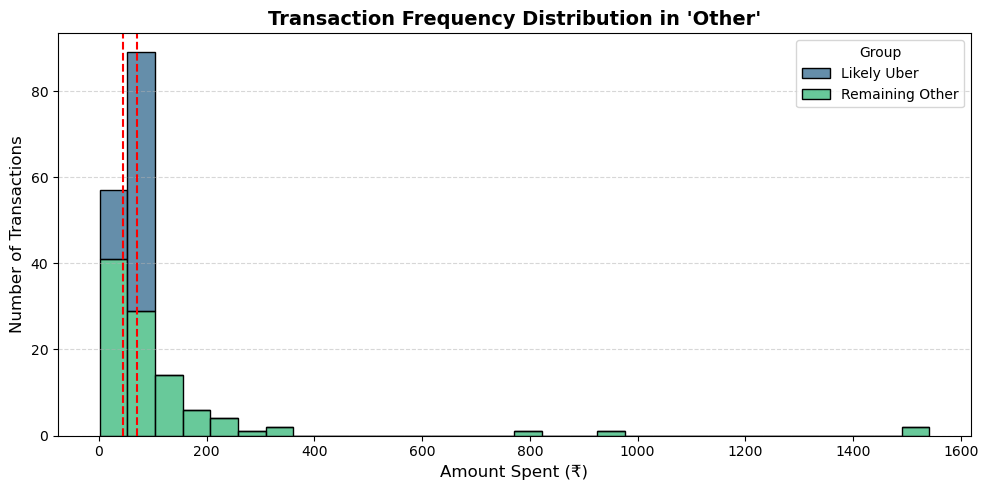

In [70]:
df["Time"]=pd.to_datetime(df["Time"],format="%I:%M%p")
commute = ((df["Category"] == "Other") & (df["Transaction_Type"] == "Paid") &
           (df["Amount"].between(45, 70)) &(df["Time"].dt.hour.between(7, 12))
        )

uberrides = df[commute].copy()
uberrides["Group"] = "Likely Uber"

uncategorised = df[(df["Category"] == "Other") & (df["Transaction_Type"] == "Paid") & (~commute)].copy()
uncategorised["Group"] = "Remaining Other"

scatterdf = pd.concat([uberrides, uncategorised])

plt.figure(figsize=(10, 5))

sns.histplot(
    data=scatterdf,
    x="Amount",
    hue="Group",
    palette="viridis",
    bins=30,
    multiple="stack"
)

plt.axvline(45, color="red", linestyle="--", label="Commute Fare Window (₹45–₹70)")
plt.axvline(70, color="red", linestyle="--")

plt.title("Transaction Frequency Distribution in 'Other'", fontsize=14, fontweight="bold")
plt.xlabel("Amount Spent (₹)", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
plt.close()

A substantial proportion of otherwise uncategorised transactions occurred within the ₹47–₹80 range, consistent with the user's typical ride-hailing expenditure. However, these transactions were retained under Other because the available merchant information did not reliably identify them as transport expenses.

g. CUMULATIVE SPENDING OVER TIME

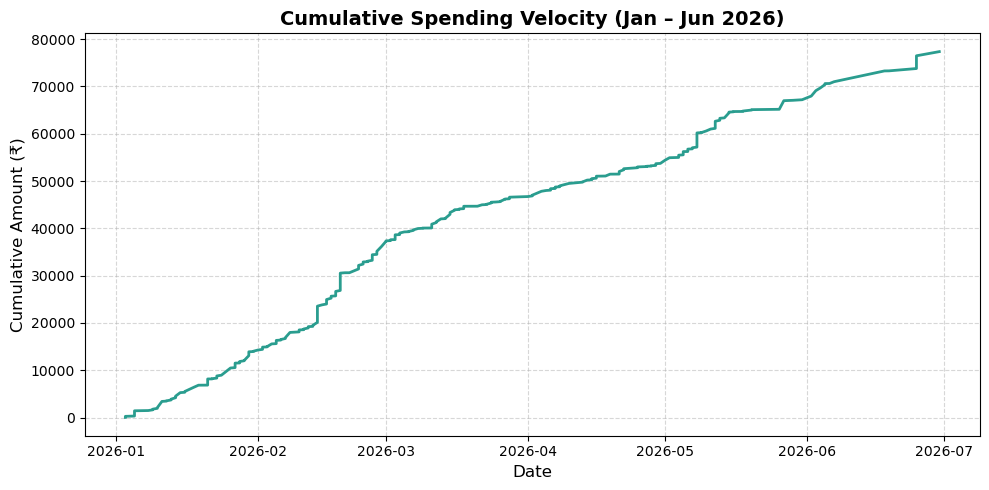

In [71]:
paid_df = df[df["Transaction_Type"] == "Paid"].sort_values("Date").copy()
paid_df["Cumulative_Spent"] = paid_df["Amount"].cumsum()

plt.figure(figsize=(10, 5))
plt.plot(paid_df["Date"], paid_df["Cumulative_Spent"], color="#2a9d8f", linewidth=2)
plt.title("Cumulative Spending Velocity (Jan – Jun 2026)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Cumulative Amount (₹)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
plt.close()

h. TIME OF THE DAY SPENDING HEATMAP

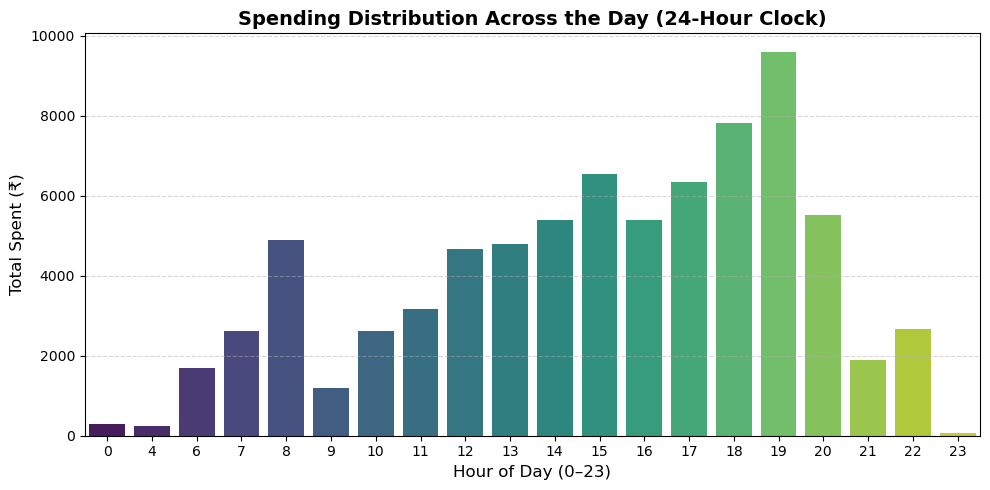

In [72]:
plt.figure(figsize=(10, 5))
hourly_spending = paid_df.groupby(paid_df["Time"].dt.hour)["Amount"].sum().reset_index()

ax = sns.barplot(
    data=hourly_spending,
    x="Time",
    y="Amount",
    palette="viridis"
)

plt.title("Spending Distribution Across the Day (24-Hour Clock)", fontsize=14, fontweight="bold")
plt.xlabel("Hour of Day (0–23)", fontsize=12)
plt.ylabel("Total Spent (₹)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
plt.close()

7. TOP 10 MOST FREQUENT MERCHANTS

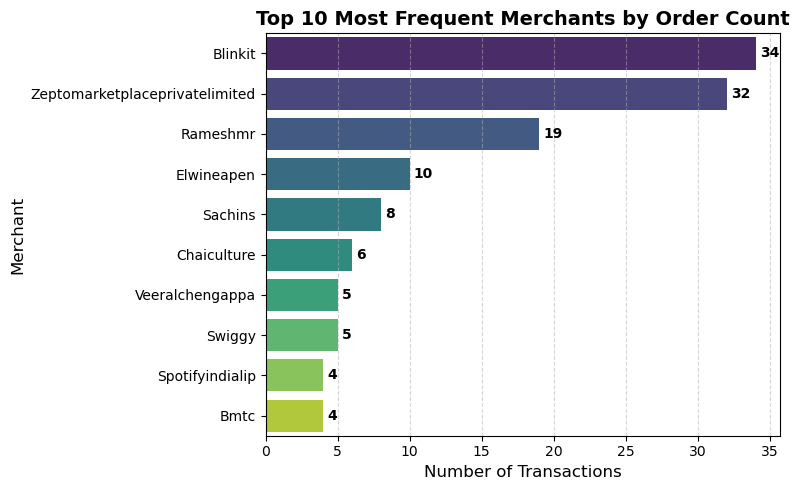

In [73]:
top_merchants = (
    paid_df["Merchant"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_merchants.columns = ["Merchant", "Transaction_Count"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=top_merchants,
    y="Merchant",
    x="Transaction_Count",
    palette="viridis"
)
ax.bar_label(ax.containers[0], padding=3, fontweight="bold")

plt.title("Top 10 Most Frequent Merchants by Order Count", fontsize=14, fontweight="bold")
plt.xlabel("Number of Transactions", fontsize=12)
plt.ylabel("Merchant", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
plt.close()

i. KPI METRICS FOR SUMMARY

- TOTAL SPENDING

In [77]:
df[df['Transaction_Type']=='Paid']['Amount'].sum().round(2)

77368.99

- AVERAGE DAILY SPEND

In [75]:
inflow = df[df["Transaction_Type"] == "Received"]["Amount"].sum()
outflow = df[df["Transaction_Type"] == "Paid"]["Amount"].sum()

net_flow = inflow-outflow
num_days = df["Date"].nunique()

avg_daily_spend = outflow / num_days if num_days > 0 else 0

print(f"Total Inflow (Received): ₹{inflow:,.2f}")
print(f"Total Outflow (Paid):     ₹{outflow:,.2f}")
print(f"----------------------------------------")
print(f"Net Savings/Deficit:     ₹{net_flow:,.2f}")
print(f"Total Active Days:       {num_days} days")
print(f"Average Daily Spend:     ₹{avg_daily_spend:,.2f}")

Total Inflow (Received): ₹70,536.00
Total Outflow (Paid):     ₹77,368.99
----------------------------------------
Net Savings/Deficit:     ₹-6,832.99
Total Active Days:       133 days
Average Daily Spend:     ₹581.72


- LARGEST SINGLE EXPENSE

In [76]:
df[df['Transaction_Type']=='Paid']['Amount'].max()

2277.0

6. SPENDING CONCENTRATION

- The largest 10% of paid transactions (37 transactions) accounted for 51.64% of total spending. 
- Groceries were the largest contributor, accounting for 21 of these transactions and ₹20,632.07 (51.7%) of their combined value.
- Groceries, shopping and personal transfers together represented approximately 90.8% of spending within the top 10% of transactions.

7. KEY INSIGHTS

- Outgoing transfers and peer-to-peer payments are concentrated around recurrent contacts such as Veeral Chengappa and Elwin Eapen
- Regular incoming transfers are logged from MC NALINAKSHI.
- High-frequency, low-friction ordering platforms like Blinkit, Zepto, and Swiggy Instamart represent 18% of total discretionary debit transactions.
- Spending spikes during late afternoon and evening hours, heavily driven by meal deliveries and quick-commerce utility orders.


8. LIMITATIONS

1. Hardcoded Regex Rules & Categorization Overheads
- Unmapped Merchants ("Other" Bucket): Categorization relies on pre-defined regex lists. Unfamiliar local vendors or new merchant UPI handles fall into the fallback category unless updated manually.
- Lack of Dynamic Context: Regex matches keywords inside raw string descriptions without considering transaction context or transaction size (e.g., a large transfer to an individual vendor vs. a small personal reimbursement).

2. PDF Format & Structural Dependency
- Layout Sensitivity: The parsing engine relies on the specific layout and text structure of Google Pay PDF exports. Changes to Google Pay's statement formatting or using statements from other banking apps (e.g., PhonePe, Paytm, or bank-native PDFs) require modifying the extraction regex patterns.
- OCR Limitations: The current pipeline assumes digital, searchable text layers in PDFs processed via pdfplumber. Scanned or image-based PDF statements would require an Optical Character Recognition (OCR) engine like Tesseract.

3. Data Scope & Multi-Account Consolidation
- Single-Source View: The analysis is restricted to a single payment handle/statement and does not account for cash spending, credit card statements, or non-UPI net banking transfers.

9. FUTURE SCOPE

- Machine Learning / LLM Classification: Replace rule-based regex with an NLP/ML text classification model (or zero-shot LLM prompts) to dynamically categorize unknown merchants.
- Interactive Dashboard:
Connect the cleaned DataFrame output to a Streamlit app or Power BI dashboard for interactive monthly budgeting and spending visualization.